In [1]:
from torch import nn
import torch

In [2]:
batch_images = torch.rand(4, 3, 256, 256)
batch_images.shape

torch.Size([4, 3, 256, 256])

In [3]:
conv = nn.Conv2d(3, 8, kernel_size=3, padding=1, stride=1)
conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1, stride=1)
relu = nn.ReLU()
pool = nn.MaxPool2d(kernel_size=2, stride=2)

In [4]:
features = conv(batch_images)
print("conv1: ", features.shape)

activated_features = relu(features)
print("relu1: ", activated_features.shape)

pooled_features = pool(activated_features)
print("pool1: ", pooled_features.shape)

features2 = conv2(pooled_features)
print("conv2: ", features2.shape)

activated_features2 = relu(features2)
print("relu2: ", activated_features2.shape)

conv1:  torch.Size([4, 8, 256, 256])
relu1:  torch.Size([4, 8, 256, 256])
pool1:  torch.Size([4, 8, 128, 128])
conv2:  torch.Size([4, 16, 128, 128])
relu2:  torch.Size([4, 16, 128, 128])


In [5]:
block = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1, stride=1),
    nn.ReLU(),
    nn.Conv2d(8, 8, kernel_size=3, padding=1, stride=1),
    nn.ReLU()
)

In [6]:
block_features = block(batch_images)
block_features.shape

torch.Size([4, 8, 256, 256])

In [7]:
print(block[0].weight.shape)
print(block[2].weight.shape)

torch.Size([8, 3, 3, 3])
torch.Size([8, 8, 3, 3])


In [8]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, stride=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, stride=1),
            nn.ReLU()
        )
    def forward(self, x):
        return self.layers(x)

In [9]:
block = DoubleConv(3, 8)
block_features = block(batch_images)

block_features.shape

torch.Size([4, 8, 256, 256])

In [10]:
deeper_block = DoubleConv(8, 16)
deeper_features = deeper_block(pool(block_features))

deeper_features.shape

torch.Size([4, 16, 128, 128])

In [11]:
upconv = nn.ConvTranspose2d(16, 8, kernel_size=2, stride=2)
upsampled_features = upconv(deeper_features)

upsampled_features.shape, block_features.shape

(torch.Size([4, 8, 256, 256]), torch.Size([4, 8, 256, 256]))

In [12]:
combined_features = torch.cat(
    (block_features, upsampled_features),
    dim=1
)

combined_features.shape

torch.Size([4, 16, 256, 256])

In [13]:
decoder_block = DoubleConv(16, 8)
decoder_features = decoder_block(combined_features)

decoder_features.shape

torch.Size([4, 8, 256, 256])

In [14]:
head = nn.Conv2d(8, 1, kernel_size=1)
logits = head(decoder_features)

print(logits.shape)
print(logits.min().item(), logits.max().item())

torch.Size([4, 1, 256, 256])
-0.1736079752445221 -0.12331772595643997


In [21]:
class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = DoubleConv(3, 8)
        self.pool = nn.MaxPool2d(2, stride=2)
        self.bottleneck = DoubleConv(8, 16)
        self.upconv = nn.ConvTranspose2d(16, 8, kernel_size=2, stride=2)
        self.decoder = DoubleConv(16, 8)
        self.head = nn.Conv2d(8, 1, kernel_size=1)

    def forward(self, x):
        skip_connection1 = self.encoder(x)
        bottleneck = self.bottleneck(self.pool(skip_connection1))
        upsampled = self.upconv(bottleneck)

        combined = torch.cat((upsampled, skip_connection1), dim=1)
        logits = self.head(self.decoder(combined))

        return logits

In [22]:
model = MiniUNet()
logits = model(batch_images)
print(logits.shape)

torch.Size([4, 1, 256, 256])


In [27]:
batch_masks = torch.zeros_like(logits)
criterion = nn.BCEWithLogitsLoss()
loss = criterion(logits, batch_masks)

print(loss.shape)
print(loss.item())

torch.Size([])
0.6639283895492554


In [28]:
model.zero_grad(set_to_none=True)

logits = model(batch_images)
loss = criterion(logits, batch_masks)
loss.backward()

In [29]:
print(model.head.weight.grad.abs().mean().item())
print(model.encoder.layers[0].weight.grad.abs().mean().item())

0.00040659678052179515
0.00033968707430176437


In [30]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [31]:
optimizer.zero_grad(set_to_none=True)

logits = model(batch_images)
loss = criterion(logits, batch_masks)
loss_before = loss.item()

loss.backward()
optimizer.step()

In [32]:
with torch.no_grad():
    loss_after = criterion(model(batch_images), batch_masks).item()

print(loss_before, loss_after)

0.6639283895492554 0.6616773009300232


In [33]:
with torch.no_grad():
    logits = model(batch_images)
    probabilities = torch.sigmoid(logits)
    predicted_masks = probabilities >= 0.5

print(probabilities.min().item(), probabilities.max().item())
print(predicted_masks.shape, predicted_masks.dtype)

0.48066407442092896 0.4855794310569763
torch.Size([4, 1, 256, 256]) torch.bool


## Sprawdzenie na rzeczywistych obrazach MRI

In [34]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
import torch
from torch.utils.data import Dataset, DataLoader

In [35]:
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

metadata_dir = project_root / "data" / "metadata"
split_dir = project_root / "data" / "splits"

In [37]:
pairs_df = pd.read_csv(metadata_dir / "pairs.csv")
splits_df = pd.read_csv(split_dir / "splits.csv")

pairs_with_split = pairs_df.merge(
    splits_df,
    on="patient_id",
    how="left",
    validate="many_to_one",
)

train_df = pairs_with_split[pairs_with_split["split"] == "train"]

In [38]:
example_df = pd.concat(
    [
        train_df[train_df["has_annotation"]].head(2),
        train_df[~train_df["has_annotation"]].head(2),
    ],
    ignore_index=True,
)

In [83]:
example_df

,patient_id,image_path,mask_path,correct_shape,slice_id,foreground_pixels,has_annotation,split
0,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,11,1426,True,train
1,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,12,2646,True,train
2,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,1,0,False,train
3,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,2,0,False,train


In [54]:
def preprocess_pair(image, mask):
    image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255
    mask_tensor = torch.from_numpy(mask > 0).float().unsqueeze(0)

    return (image_tensor, mask_tensor)

In [55]:
class MRIDataset(Dataset):
    def __init__(self, pairs_df, project_root):
        self.pairs_df = pairs_df
        self.project_root = project_root

    def __len__(self):
        return self.pairs_df.shape[0]

    def __getitem__(self, index):
        row = self.pairs_df.iloc[index]
        image_path = self.project_root / row["image_path"]
        mask_path = self.project_root / row["mask_path"]
        return preprocess_pair(tifffile.imread(image_path), tifffile.imread(mask_path))

In [56]:
example_dataset = MRIDataset(example_df, project_root)

example_loader = DataLoader(
    example_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

In [57]:
real_images, real_masks = next(iter(example_loader))

In [58]:
print(real_images.shape, real_images.dtype)
print(real_masks.shape, real_masks.dtype)
print(torch.unique(real_masks))
print(real_masks.sum(dim=(1, 2, 3)))

torch.Size([4, 3, 256, 256]) torch.float32
torch.Size([4, 1, 256, 256]) torch.float32
tensor([0., 1.])
tensor([1426., 2646.,    0.,    0.])


In [59]:
real_model = MiniUNet()
real_model.eval()

with torch.no_grad():
    real_logits = real_model(real_images)
    real_probabilities = torch.sigmoid(real_logits)
    real_predictions = real_probabilities >= 0.5

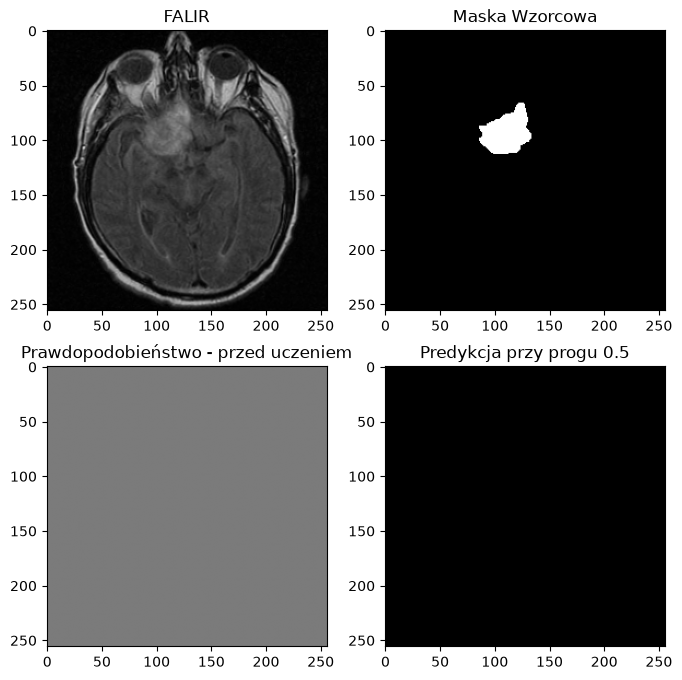

In [63]:
i = 0 
fig, ax = plt.subplots(2, 2, figsize=(8, 8))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FALIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - przed uczeniem")

ax[1, 1].imshow(real_predictions[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Predykcja przy progu 0.5")

plt.show()

In [65]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

real_model = real_model.to(device)
training_images = real_images.to(device)
training_masks = real_masks.to(device)

real_optimizer = torch.optim.Adam(real_model.parameters(), lr=1e-3)

print(device)

cuda


In [66]:
real_model.train()

for step in range(100):
    real_optimizer.zero_grad(set_to_none=True)
    logits = real_model(training_images)
    loss = criterion(logits, training_masks)
    loss.backward()
    real_optimizer.step()

    if (step + 1) % 20 == 0:
        print(step + 1, loss.item())

20 0.5630109906196594
40 0.13461719453334808
60 0.10247935354709625
80 0.0780668631196022
100 0.06324446946382523


In [67]:
real_model.eval()

with torch.no_grad():
    real_logits = real_model(training_images)
    real_probabilities = torch.sigmoid(real_logits).cpu()
    real_predictions = real_probabilities >= 0.5

In [68]:
print("Wzorzec:", real_masks.sum(dim=(1, 2, 3)))
print("Predykcja:", real_predictions.sum(dim=(1, 2, 3)))

intersection = real_predictions & (real_masks > 0)
print("Część wspólna:", intersection.sum(dim=(1, 2, 3)))

Wzorzec: tensor([1426., 2646.,    0.,    0.])
Predykcja: tensor([0, 0, 0, 0])
Część wspólna: tensor([0, 0, 0, 0])


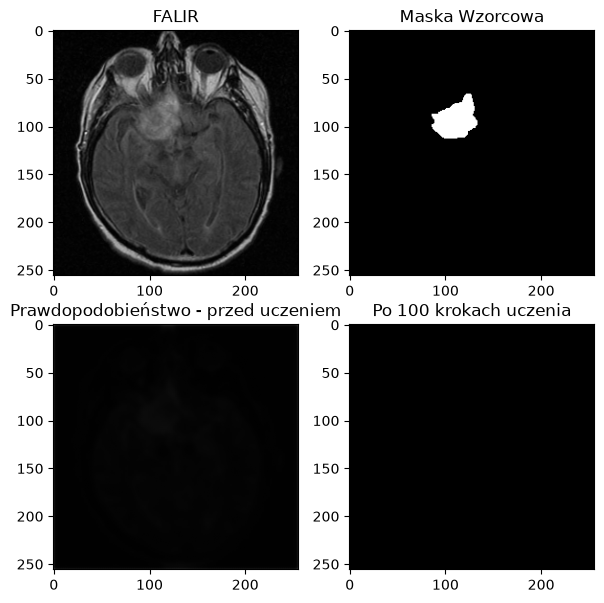

In [79]:
i = 0 
fig, ax = plt.subplots(2, 2, figsize=(7, 7))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FALIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - przed uczeniem")

ax[1, 1].imshow(real_predictions[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Po 100 krokach uczenia")

plt.show()

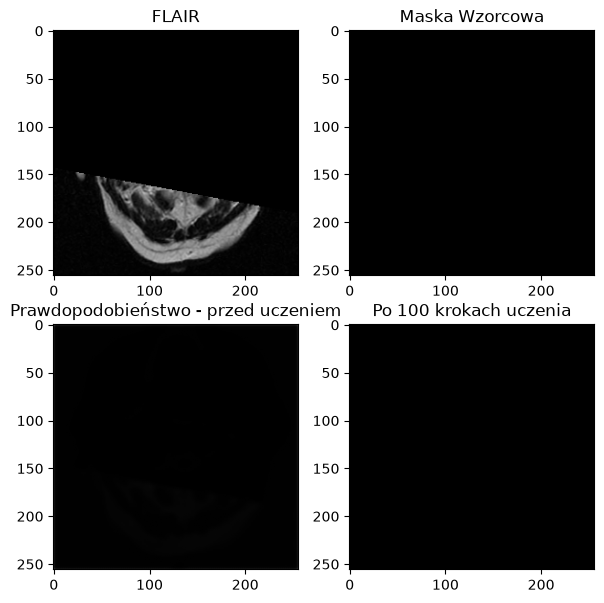

In [101]:
i = 2 
fig, ax = plt.subplots(2, 2, figsize=(7, 7))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FLAIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - przed uczeniem")

ax[1, 1].imshow(real_predictions[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Po 100 krokach uczenia")

plt.show()

In [80]:
foreground = real_masks > 0

print("Maksimum w całej paczce:",
      real_probabilities.max().item())

print("Średnia w oznaczeniu:",
      real_probabilities[foreground].mean().item())

print("Średnia poza oznaczeniem:",
      real_probabilities[~foreground].mean().item())

print("Maksimum w oznaczeniu:",
      real_probabilities[foreground].max().item())

Maksimum w całej paczce: 0.3234773576259613
Średnia w oznaczeniu: 0.04008464515209198
Średnia poza oznaczeniem: 0.012478991411626339
Maksimum w oznaczeniu: 0.05580789968371391
